<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Dataset Generation and Task 1: Load and Standardize Data
We will first generate a synthetic dataset representing 200 patient records with correlated blood parameters: Haemoglobin, RBC count, Glucose, Cholesterol, and BMI. Then we will standardize each feature (mean = 0, variance = 1).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
np.random.seed(42)

# Generate synthetic correlated data for 200 patients
mean = [14, 4.5, 100, 200, 25]  # Haemoglobin, RBC, Glucose, Cholesterol, BMI
cov = [
    [4.0, 1.2, 0.5, 2.0, 1.5],
    [1.2, 0.8, 0.1, 0.5, 0.4],
    [0.5, 0.1, 400.0, 80.0, 15.0],
    [2.0, 0.5, 80.0, 1600.0, 30.0],
    [1.5, 0.4, 15.0, 30.0, 25.0]
]

data = np.random.multivariate_normal(mean, cov, size=200)
columns = ['Haemoglobin', 'RBC_Count', 'Glucose', 'Cholesterol', 'BMI']
df = pd.DataFrame(data, columns=columns)

# Standardize the features (mean = 0, std = 1)
df_standardized = (df - df.mean()) / df.std()

print("Standardized dataset sample:")
display(df_standardized.head())

Standardized dataset sample:


,Haemoglobin,RBC_Count,Glucose,Cholesterol,BMI
0,1.538429,1.325198,0.041455,-0.550864,0.557476
1,-0.363024,-0.626365,-1.580907,0.289574,0.615408
2,-2.118075,-0.215117,0.501386,0.462573,0.460581
3,-1.052651,0.320825,1.061848,0.548413,0.598233
4,-1.590586,-0.692608,0.003513,-1.586254,-0.090149


### Task 2: Compute Covariance and Correlation Matrices; Plot Heatmaps

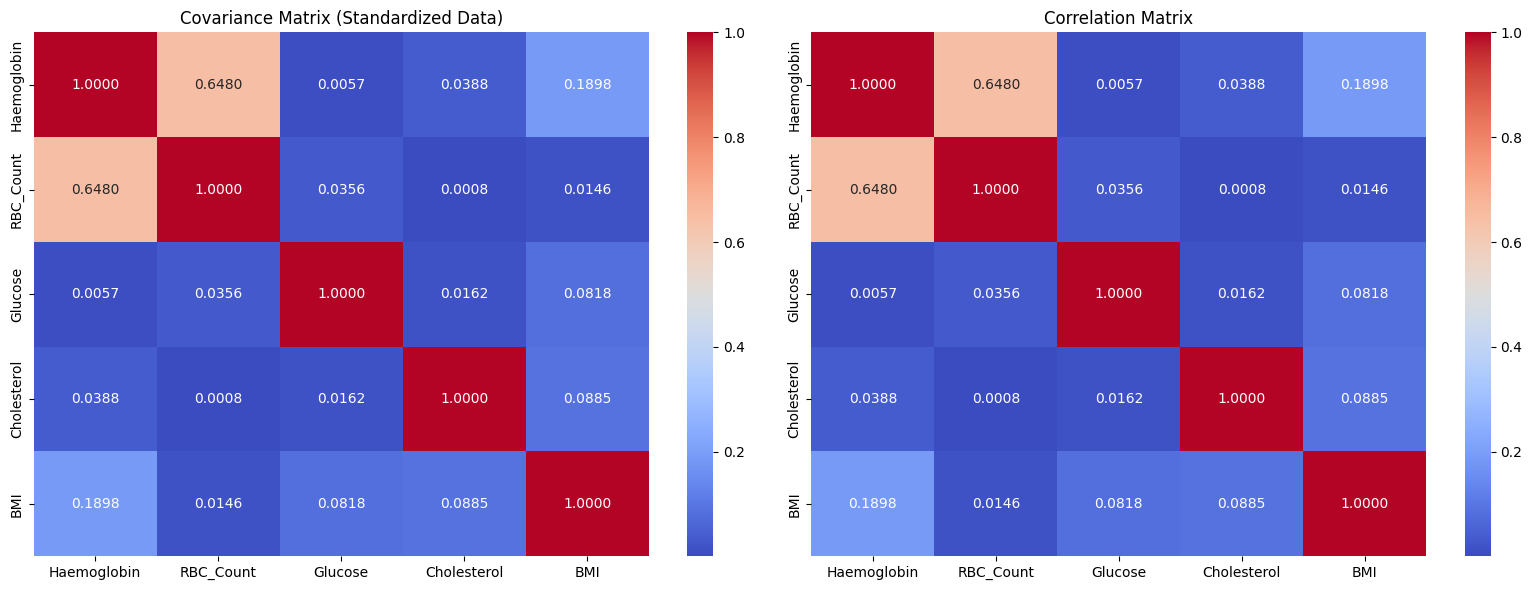

In [2]:
# Compute covariance and correlation matrices of standardized data
cov_matrix = df_standardized.cov()
corr_matrix = df_standardized.corr()

# Plot Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cov_matrix, annot=True, cmap='coolwarm', fmt='.4f', ax=axes[0])
axes[0].set_title('Covariance Matrix (Standardized Data)')

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.4f', ax=axes[1])
axes[1].set_title('Correlation Matrix')

plt.tight_layout()
plt.show()

### Task 3: Compute Eigenvalues and Eigenvectors; Sort by Eigenvalue

In [3]:
# Compute eigenvalues and eigenvectors using NumPy
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix.values)

# Sort eigenvalues and corresponding eigenvectors in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Sorted Eigenvalues:")
for idx, val in enumerate(eigenvalues):
    print(f"Principal Component {idx+1}: {val:.4f}")

print("\nSorted Eigenvectors (columns correspond to PCs):")
display(pd.DataFrame(eigenvectors, index=columns, columns=[f'PC{i+1}' for i in range(len(eigenvalues))]))

Sorted Eigenvalues:
Principal Component 1: 1.6857
Principal Component 2: 1.1091
Principal Component 3: 0.9858
Principal Component 4: 0.8928
Principal Component 5: 0.3266

Sorted Eigenvectors (columns correspond to PCs):


,PC1,PC2,PC3,PC4,PC5
Haemoglobin,-0.700190,0.081085,0.042170,0.036519,-0.707141
RBC_Count,-0.670084,0.236901,-0.038709,-0.179475,0.679084
Glucose,-0.069160,-0.476500,-0.775280,-0.405293,-0.053322
Cholesterol,-0.071168,-0.554868,0.628580,-0.540068,0.016438
BMI,-0.225553,-0.634329,0.023475,0.714506,0.188899


### Task 4: Plot Data in 2-D with Top Two Eigenvectors Drawn as Arrows
We will project the standardized Haemoglobin and RBC Count data to 2-D, compute their principal components, and plot them alongside the principal directions.

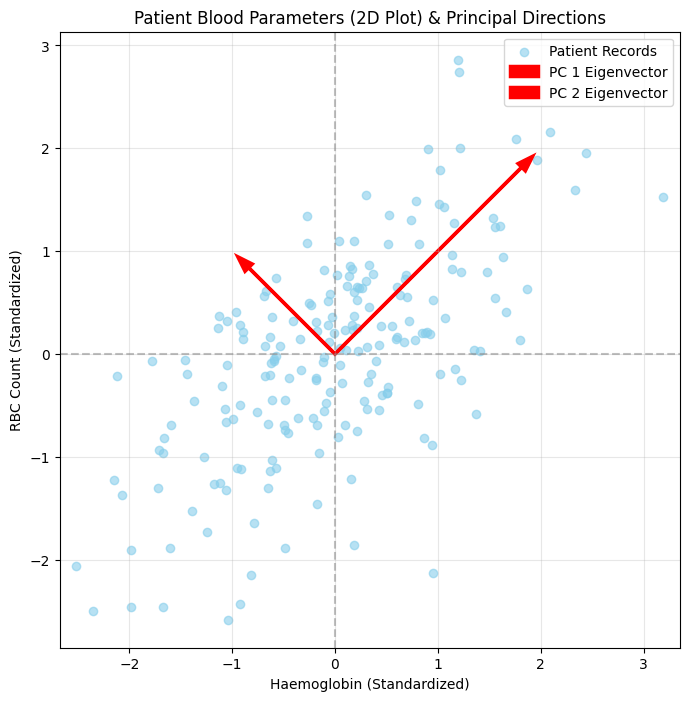

In [4]:
# Using the first two variables (Haemoglobin and RBC Count) to demonstrate 2-D eigenvectors
X_2d = df_standardized[['Haemoglobin', 'RBC_Count']].values
cov_2d = np.cov(X_2d.T)
evals_2d, evecs_2d = np.linalg.eig(cov_2d)

# Sort
idx_2d = np.argsort(evals_2d)[::-1]
evals_2d = evals_2d[idx_2d]
evecs_2d = evecs_2d[:, idx_2d]

plt.figure(figsize=(8, 8))
plt.scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.6, color='skyblue', label='Patient Records')

# Draw eigenvectors as arrows scaled by their eigenvalue strength
mean_point = [0, 0]
for i in range(2):
    v = evecs_2d[:, i] * np.sqrt(evals_2d[i]) * 2.0  # scale for visual impact
    plt.arrow(mean_point[0], mean_point[1], v[0], v[1],
              head_width=0.1, head_length=0.15, fc='red', ec='red', linewidth=2.5,
              label=f'PC {i+1} Eigenvector' if i == 0 else 'PC 2 Eigenvector')

plt.xlabel('Haemoglobin (Standardized)')
plt.ylabel('RBC Count (Standardized)')
plt.title('Patient Blood Parameters (2D Plot) & Principal Directions')
plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

### Task 5: Report the Percentage of Variance Captured by Each Eigenvalue

Variance Contribution Report:


,Eigenvalue,Percentage of Variance Explained (%),Cumulative Variance (%)
PC 1,1.685750,33.714995,33.714995
PC 2,1.109085,22.181699,55.896694
PC 3,0.985825,19.716510,75.613203
PC 4,0.892772,17.855439,93.468643
PC 5,0.326568,6.531357,100.000000


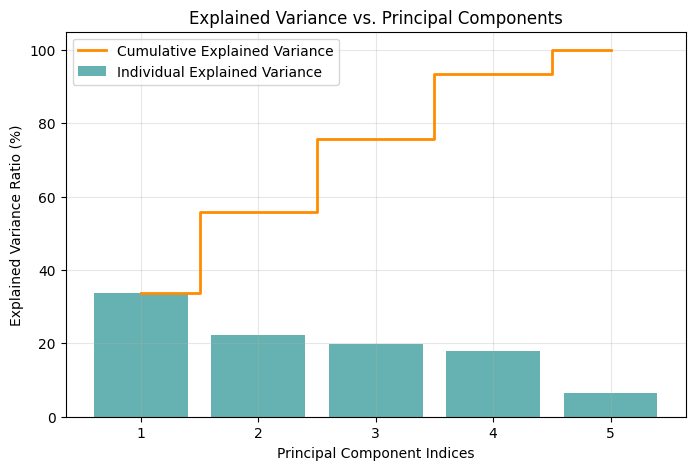

In [5]:
total_variance = np.sum(eigenvalues)
explained_variance_ratio = (eigenvalues / total_variance) * 100
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print("Variance Contribution Report:")
variance_report = pd.DataFrame({
    'Eigenvalue': eigenvalues,
    'Percentage of Variance Explained (%)': explained_variance_ratio,
    'Cumulative Variance (%)': cumulative_variance_ratio
}, index=[f'PC {i+1}' for i in range(len(eigenvalues))])

display(variance_report)

# Plotting Cumulative Explained Variance
plt.figure(figsize=(8, 5))
plt.bar(range(1, 6), explained_variance_ratio, alpha=0.6, align='center', label='Individual Explained Variance', color='teal')
plt.step(range(1, 6), cumulative_variance_ratio, where='mid', label='Cumulative Explained Variance', color='darkorange', linewidth=2)
plt.ylabel('Explained Variance Ratio (%)')
plt.xlabel('Principal Component Indices')
plt.title('Explained Variance vs. Principal Components')
plt.xticks(range(1, 6))
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()